In [2]:
from langchain_openai import ChatOpenAI

from dotenv import load_dotenv
import os
load_dotenv()

if os.environ['OPENAI_API_KEY'] :
    print("OpenAI API key is set.")
else:
    print("OpenAI API key is not set.")

OpenAI API key is set.


In [3]:
llm = ChatOpenAI(model="gpt-5-nano")
llm.invoke("i WANT TO KNOW THE MEANING OF WATER").content

'Water has a few related but different meanings depending on the context. Here are the main ones:\n\n1) Scientific meaning (what it is)\n- Water is a chemical compound with the formula H2O: two hydrogen atoms bonded to one oxygen atom.\n- It can be a solid (ice), liquid (water), or gas (water vapor) depending on temperature and pressure.\n- It’s known for being a very good solvent, has a high heat capacity, and expands when it freezes. Its molecules stick together (cohesion) and to surfaces (adhesion).\n\n2) Everyday meaning (how we use it)\n- Usually referring to the liquid we drink, cook with, bathe in, or use for washing.\n- In nature, it includes rivers, lakes, rain, seawater, and groundwater.\n- The term “water” is often distinguished from other liquids (like oil or juice) by its purity and freshness for human use.\n\n3) Biological/environmental meaning\n- Water is essential for all known life.\n- Earth’s water cycle describes how water moves through the environment: evaporation, 

### PYDENTIC SCHEMA

In [4]:
from pydantic import BaseModel, Field

class graph_schema(BaseModel):
    topic: str = Field(..., description="The topic of the graph")
    post: str = Field(..., description="The content of the linkedin post")
    curated_post: str = Field(..., description="The curated content of the linkedin post")

demo_graph = graph_schema(
    topic="The Importance of privacy in the digital world",
    post="In today's digital age, privacy is more important than ever.",
    curated_post="Protecting personal information is crucial in the digital world."
)

In [5]:
def create_post(state: graph_schema) -> graph_schema:
    state = state.model_dump()

    #Extract topic from state
    topic = state['topic']

    #Passing the topic to llm to generate the post 
    post = llm.invoke(f"Create a linkedin post about {topic}").content

    state['post'] = post
    return state


def curate_post(state: graph_schema) -> graph_schema:
    state = state.model_dump()

    #Extract post from state
    post = state['post']

    #Passing the post to llm to curate it
    curated_post = llm.invoke(f"Curate the following linkedin post: {post}").content

    state['curated_post'] = curated_post
    return state

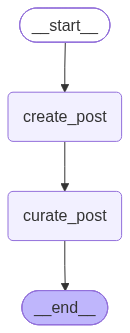

In [8]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

graph.add_node("create_post",create_post)
graph.add_node("curate_post",curate_post)

graph.add_edge(START,"create_post")
graph.add_edge("create_post", "curate_post")
graph.add_edge("curate_post", END)

pydantic_graph = graph.compile()

from IPython.display import display, Image

first_graph=graph.compile()

Image(first_graph.get_graph().draw_mermaid_png())


In [9]:
pydantic_graph.invoke(
    {"topic": "Artificial Intelligence",
     "post": "",
     "curated_post": ""})

{'topic': 'Artificial Intelligence',
 'post': "Here are a few ready-to-use LinkedIn post options about Artificial Intelligence. Pick the one that fits your voice, or mix elements from multiple options.\n\nOption A — Primary, thoughtful and engaging (about 170–190 words)\nArtificial Intelligence isn't the future—it's the present. It's the force multiplier that helps teams move faster, decide smarter, and innovate more boldly. From automating repetitive workflows to surfacing insights that used to take weeks, AI is reshaping every industry.\n\nIn healthcare, AI accelerates diagnostics; in manufacturing, it optimizes supply chains; in finance, it detects risks and personalizes experiences at scale; in education, it personalizes learning journeys. The common thread: AI amplifies human expertise, not substitutes it. The best AI work is grounded in real problems and built through close collaboration between data scientists and domain experts.\n\nBut with power comes responsibility. Data qual